In [1]:
# TASK 1:

import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/jakevdp/data-CDCbirths/master/births.csv"
df = pd.read_csv(url)

print("First five rows:")
print(df.head())

print("\nShape of dataset:")
print(df.shape)

print("\nColumn data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nExplanation:")
print("The day column is stored as an object because it contains")
print("text or inconsistently formatted values rather than only integers.")

First five rows:
   year  month  day gender  births
0  1969      1  1.0      F    4046
1  1969      1  1.0      M    4440
2  1969      1  2.0      F    4454
3  1969      1  2.0      M    4548
4  1969      1  3.0      F    4548

Shape of dataset:
(15547, 5)

Column data types:
year        int64
month       int64
day       float64
gender     object
births      int64
dtype: object

Missing values:
year        0
month       0
day       480
gender      0
births      0
dtype: int64

Explanation:
The day column is stored as an object because it contains
text or inconsistently formatted values rather than only integers.


Total births by decade and gender:
gender         F         M
decade                    
1960     1753634   1846572
1970    16263075  17121550
1980    18310351  19243452
1990    19479454  20420553
2000    18229309  19106428

Ratio and percentage difference:
gender         F         M  Male-to-female ratio  Male excess percentage
decade                                                                  
1960     1753634   1846572              1.052997                5.299738
1970    16263075  17121550              1.052787                5.278676
1980    18310351  19243452              1.050960                5.096030
1990    19479454  20420553              1.048312                4.831239
2000    18229309  19106428              1.048116                4.811587


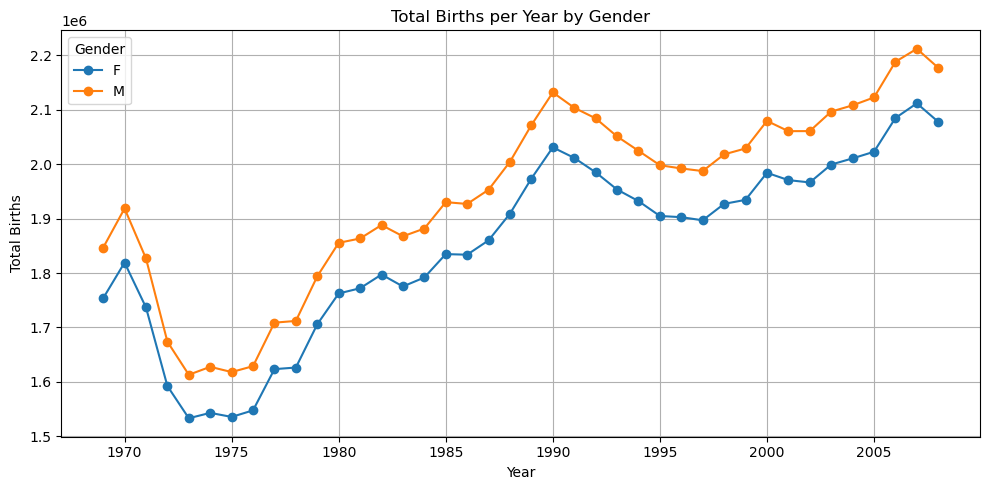

In [3]:
# TASK 2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
url = "https://raw.githubusercontent.com/jakevdp/data-CDCbirths/master/births.csv"
df = pd.read_csv(url)
df["decade"] = (df["year"] // 10) * 10

pivot = pd.pivot_table(
    df,
    values="births",
    index="decade",
    columns="gender",
    aggfunc="sum",
    fill_value=0
)
print("Total births by decade and gender:")
print(pivot)
pivot["Male-to-female ratio"] = pivot["M"] / pivot["F"]
pivot["Male excess percentage"] = (
    (pivot["M"] - pivot["F"]) / pivot["F"]
) * 100
print("\nRatio and percentage difference:")
print(pivot)
yearly = pd.pivot_table(
    df,
    values="births",
    index="year",
    columns="gender",
    aggfunc="sum",
    fill_value=0
)
yearly.plot(figsize=(10, 5), marker="o")
plt.title("Total Births per Year by Gender")
plt.xlabel("Year")
plt.ylabel("Total Births")
plt.legend(title="Gender")
plt.grid(True)
plt.tight_layout()
plt.show()

In [5]:
# TASK 3
import pandas as pd
import numpy as np
url = "https://raw.githubusercontent.com/jakevdp/data-CDCbirths/master/births.csv"
df = pd.read_csv(url)
df["births"] = pd.to_numeric(df["births"], errors="coerce")
df = df.dropna(subset=["births"]).copy()
Q1 = np.percentile(df["births"], 25)
Q3 = np.percentile(df["births"], 75)

mu = df["births"].median()
sigma = 0.74 * (Q3 - Q1)

print("Q1:", Q1)
print("Q3:", Q3)
print("Robust mean (median):", mu)
print("Robust standard deviation:", sigma)
before = len(df)
df = df.query(
    "@mu - 5 * @sigma <= births <= @mu + 5 * @sigma"
).copy()

after = len(df)
print("\nRows before cleaning:", before)
print("Rows after cleaning:", after)
print("Rows removed:", before - after)
df["day"] = (
    df["day"].astype(str)
    .str.extract(r"(\d+)", expand=False)
)
df = df.dropna(subset=["day"]).copy()
df["day"] = df["day"].astype(int)
print("\nData types after cleaning:")
print(df.dtypes)
print("\nFirst five cleaned rows:")
print(df.head())
print("\nThe factor 0.74 approximates 1/1.349.")
print("For normally distributed data, IQR is approximately 1.349")
print("standard deviations, so 0.74 * IQR estimates the standard deviation.")

Q1: 4358.0
Q3: 5289.5
Robust mean (median): 4814.0
Robust standard deviation: 689.31

Rows before cleaning: 15547
Rows after cleaning: 14610
Rows removed: 937

Data types after cleaning:
year       int64
month      int64
day        int32
gender    object
births     int64
dtype: object

First five cleaned rows:
   year  month  day gender  births
0  1969      1    1      F    4046
1  1969      1    1      M    4440
2  1969      1    2      F    4454
3  1969      1    2      M    4548
4  1969      1    3      F    4548

The factor 0.74 approximates 1/1.349.
For normally distributed data, IQR is approximately 1.349
standard deviations, so 0.74 * IQR estimates the standard deviation.


Mean births by weekday and decade:
decade             1960         1970          1980
weekday                                           
Monday     10127.653846  9378.195402  10553.814499
Tuesday    10572.192308  9770.504798  11007.685106
Wednesday  10149.245283  9500.752399  10735.285106
Thursday    9956.576923  9393.846743  10666.970213
Friday     10215.769231  9564.191571  10786.174468
Saturday    9302.115385  8415.568966   8967.802128
Sunday      8684.692308  7958.557471   8616.240938


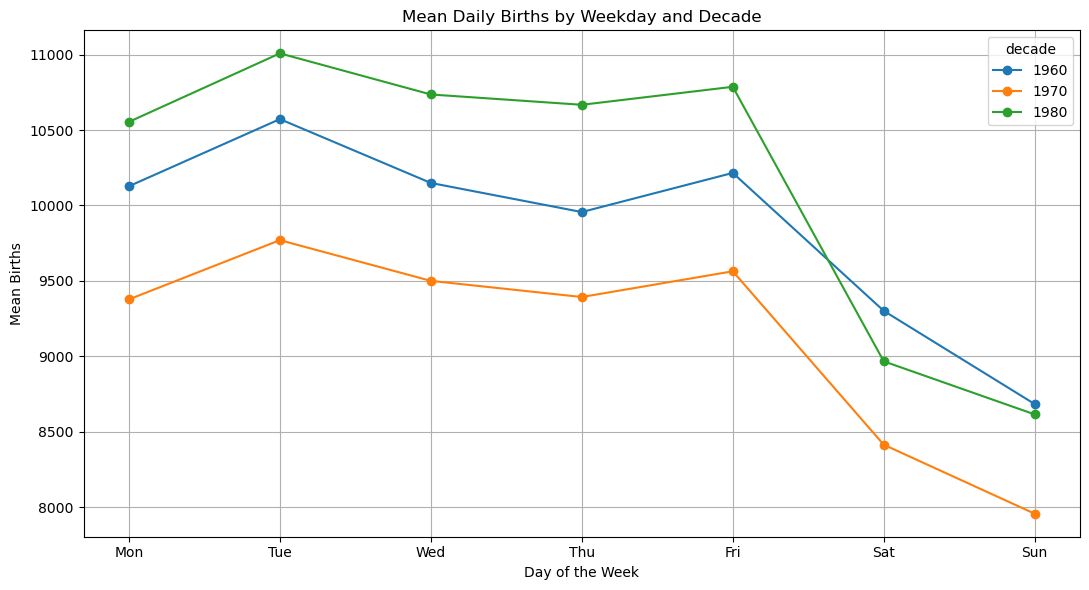


Observation:
Birth counts are often lower on weekends because fewer
deliveries are scheduled on Saturdays and Sundays.
Only decades available in the dataset appear in the plot.


In [7]:
# TASK 4:9
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/jakevdp/data-CDCbirths/master/births.csv"
df = pd.read_csv(url)
for col in ["year", "month", "births"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["day"] = (
    df["day"].astype(str)
    .str.extract(r"(\d+)", expand=False)
)
df["day"] = pd.to_numeric(df["day"], errors="coerce")
df = df.dropna(subset=["year", "month", "day", "births"]).copy()
df["date"] = pd.to_datetime(
    {
        "year": df["year"],
        "month": df["month"],
        "day": df["day"]
    },
    errors="coerce"
)
df = df.dropna(subset=["date"]).copy()
df["year"] = df["year"].astype(int)
df["decade"] = (df["year"] // 10) * 10
df["weekday"] = df["date"].dt.day_name()
daily = df.groupby(
    ["date", "decade", "weekday"],
    as_index=False
)["births"].sum()
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]
daily["weekday"] = pd.Categorical(
    daily["weekday"],
    categories=weekday_order,
    ordered=True
)
pivot = pd.pivot_table(
    daily,
    values="births",
    index="weekday",
    columns="decade",
    aggfunc="mean",
    observed=False
)

print("Mean births by weekday and decade:")
print(pivot)


pivot.plot(figsize=(11, 6), marker="o")

plt.title("Mean Daily Births by Weekday and Decade")
plt.xlabel("Day of the Week")
plt.ylabel("Mean Births")
plt.xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nObservation:")
print("Birth counts are often lower on weekends because fewer")
print("deliveries are scheduled on Saturdays and Sundays.")
print("Only decades available in the dataset appear in the plot.")

Mean births by calendar date:
            mean_births
date                   
2012-01-01      8018.45
2012-01-02      8494.80
2012-01-03      9001.80
2012-01-04      9142.70
2012-01-05      9207.25
2012-01-06      9336.30
2012-01-07      9413.85
2012-01-08      9259.30
2012-01-09      9075.55
2012-01-10      9183.40


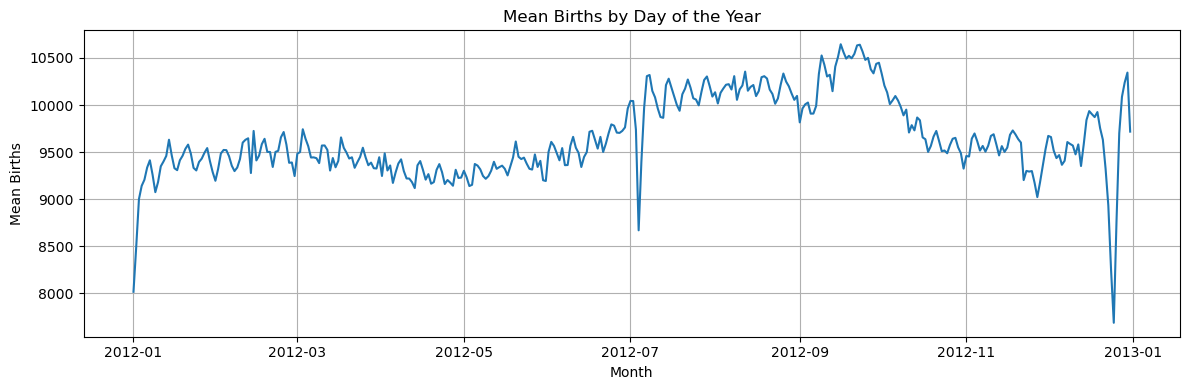


Observation:
Birth counts may show dips on holidays and weekends.
These patterns may reflect scheduled delivery practices.


In [9]:
# TASK 5
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
url = "https://raw.githubusercontent.com/jakevdp/data-CDCbirths/master/births.csv"
df = pd.read_csv(url)
for col in ["year", "month", "births"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["day"] = (
    df["day"].astype(str)
    .str.extract(r"(\d+)", expand=False)
)
df["day"] = pd.to_numeric(df["day"], errors="coerce")

df = df.dropna(
    subset=["year", "month", "day", "births"]
).copy()
for col in ["year", "month", "day"]:
    df[col] = df[col].astype(int)
df["date"] = pd.to_datetime(
    {
        "year": df["year"],
        "month": df["month"],
        "day": df["day"]
    },
    errors="coerce"
)

df = df.dropna(subset=["date"]).copy()
daily_totals = df.groupby(
    ["year", "month", "day"]
)["births"].sum()


mean_births = daily_totals.groupby(
    level=["month", "day"]
).mean()


month_day = mean_births.index

dates = pd.to_datetime(
    {
        "year": 2012,
        "month": month_day.get_level_values("month"),
        "day": month_day.get_level_values("day")
    },
    errors="coerce"
)

result = pd.DataFrame({
    "date": dates,
    "mean_births": mean_births.to_numpy()
})

result = result.dropna(subset=["date"])
result = result.sort_values("date").set_index("date")

print("Mean births by calendar date:")
print(result.head(10))


plt.figure(figsize=(12, 4))
plt.plot(result.index, result["mean_births"])

plt.title("Mean Births by Day of the Year")
plt.xlabel("Month")
plt.ylabel("Mean Births")
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nObservation:")
print("Birth counts may show dips on holidays and weekends.")
print("These patterns may reflect scheduled delivery practices.")


In [11]:
# TASK 6
import pandas as pd
import numpy as np
import time
url = "https://raw.githubusercontent.com/jakevdp/data-CDCbirths/master/births.csv"
df = pd.read_csv(url)
df["decade"] = (df["year"] // 10) * 10
pivot = pd.pivot_table(
    df,
    values="births",
    index="decade",
    columns="gender",
    aggfunc="sum",
    fill_value=0
)

print("Pivot table result:")
print(pivot)
grouped = (
    df.groupby(["decade", "gender"])["births"]
    .sum()
    .unstack(fill_value=0)
)
print("\nGroupby result:")
print(grouped)
pivot, grouped = pivot.align(
    grouped,
    join="outer",
    axis=None,
    fill_value=0
)
print("\nDo both tables match?")
print(np.allclose(pivot.to_numpy(), grouped.to_numpy()))

start = time.perf_counter()

for i in range(100):
    pd.pivot_table(
        df,
        values="births",
        index="decade",
        columns="gender",
        aggfunc="sum",
        fill_value=0
    )
pivot_time = time.perf_counter() - start
start = time.perf_counter()
for i in range(100):
    (
        df.groupby(["decade", "gender"])["births"]
        .sum()
        .unstack(fill_value=0)
    )

groupby_time = time.perf_counter() - start

print("\nTime for 100 pivot_table runs:", pivot_time, "seconds")
print("Time for 100 groupby runs:", groupby_time, "seconds")

print("\nConclusion:")
print("Both methods produce the same totals when using the same")
print("grouping and aggregation. Pivot tables create a table directly,")
print("while groupby performs grouping and aggregation, and unstack")
print("converts one grouping level into columns.")

Pivot table result:
gender         F         M
decade                    
1960     1753634   1846572
1970    16263075  17121550
1980    18310351  19243452
1990    19479454  20420553
2000    18229309  19106428

Groupby result:
gender         F         M
decade                    
1960     1753634   1846572
1970    16263075  17121550
1980    18310351  19243452
1990    19479454  20420553
2000    18229309  19106428

Do both tables match?
True

Time for 100 pivot_table runs: 1.2115961000090465 seconds
Time for 100 groupby runs: 0.5803395999973873 seconds

Conclusion:
Both methods produce the same totals when using the same
grouping and aggregation. Pivot tables create a table directly,
while groupby performs grouping and aggregation, and unstack
converts one grouping level into columns.


Five dates with the lowest mean births:
            mean_births
date                   
2012-12-25      7688.90
2012-01-01      8018.45
2012-12-24      8252.50
2012-01-02      8494.80
2012-07-04      8670.65


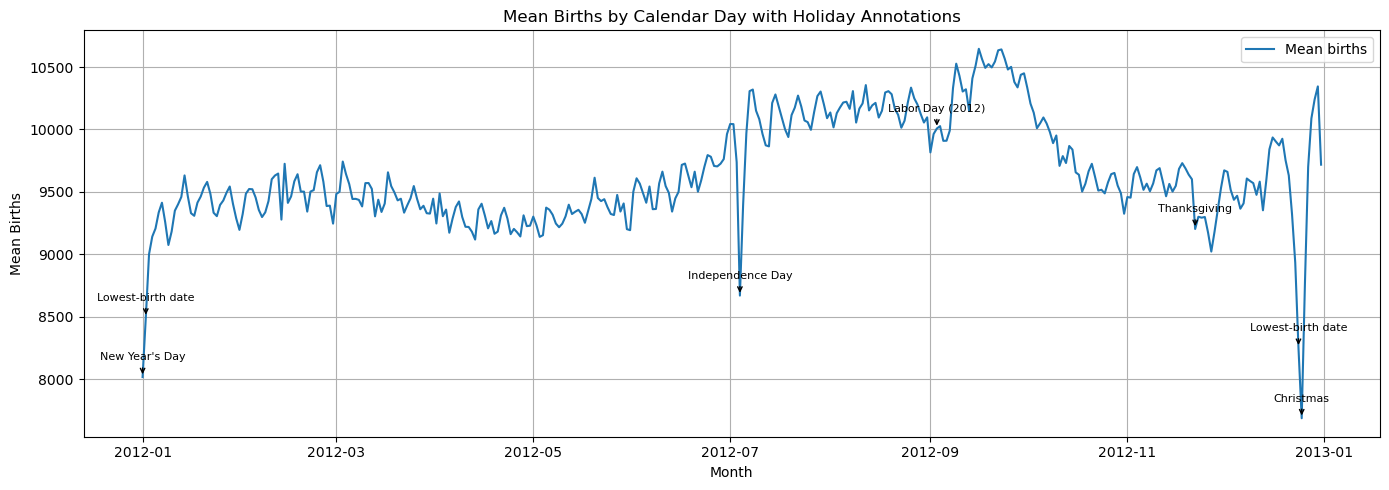


Observation:
Some dates may have lower average birth counts because of
holidays, weekends, or scheduled delivery practices.
Compare the five lowest-birth dates with the annotated holidays.


In [13]:
# BONUS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
url = "https://raw.githubusercontent.com/jakevdp/data-CDCbirths/master/births.csv"
df = pd.read_csv(url)
for col in ["year", "month", "births"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["day"] = (
    df["day"].astype(str)
    .str.extract(r"(\d+)", expand=False)
)
df["day"] = pd.to_numeric(df["day"], errors="coerce")

df = df.dropna(
    subset=["year", "month", "day", "births"]
).copy()
for col in ["year", "month", "day"]:
    df[col] = df[col].astype(int)
df["date"] = pd.to_datetime(
    {
        "year": df["year"],
        "month": df["month"],
        "day": df["day"]
    },
    errors="coerce"
)

df = df.dropna(subset=["date"]).copy()
daily_totals = df.groupby(
    ["year", "month", "day"]
)["births"].sum()
mean_births = daily_totals.groupby(
    level=["month", "day"]
).mean()
month_day = mean_births.index
dates = pd.to_datetime(
    {
        "year": 2012,
        "month": month_day.get_level_values("month"),
        "day": month_day.get_level_values("day")
    },
    errors="coerce"
)
result = pd.DataFrame({
    "date": dates,
    "mean_births": mean_births.to_numpy()
})
result = result.dropna(subset=["date"])
result = result.sort_values("date").set_index("date")
lowest_five = result.nsmallest(5, "mean_births")

print("Five dates with the lowest mean births:")
print(lowest_five)
holidays = {
    "01-01": "New Year's Day",
    "07-04": "Independence Day",
    "09-03": "Labor Day (2012)",
    "12-25": "Christmas"
}
november_first = pd.Timestamp("2012-11-01")
first_thursday_offset = (3 - november_first.dayofweek) % 7
first_thursday = november_first + pd.Timedelta(
    days=first_thursday_offset
)
thanksgiving = first_thursday + pd.Timedelta(days=21)

holidays[thanksgiving.strftime("%m-%d")] = "Thanksgiving"

plt.figure(figsize=(14, 5))
plt.plot(
    result.index,
    result["mean_births"],
    label="Mean births"
)
for date, row in lowest_five.iterrows():
    key = date.strftime("%m-%d")
    label = holidays.get(key, "Lowest-birth date")
    plt.annotate(
        label,
        xy=(date, row["mean_births"]),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        arrowprops={"arrowstyle": "->"}
    )
for key, label in holidays.items():
    date = pd.Timestamp("2012-" + key)

    if date in result.index and date not in lowest_five.index:
        plt.annotate(
            label,
            xy=(date, result.loc[date, "mean_births"]),
            xytext=(0, 12),
            textcoords="offset points",
            ha="center",
            fontsize=8,
            arrowprops={"arrowstyle": "->"}
        )
plt.title("Mean Births by Calendar Day with Holiday Annotations")
plt.xlabel("Month")
plt.ylabel("Mean Births")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print("\nObservation:")
print("Some dates may have lower average birth counts because of")
print("holidays, weekends, or scheduled delivery practices.")
print("Compare the five lowest-birth dates with the annotated holidays.")